<a href="https://colab.research.google.com/github/sorayacdacosta-stack/README/blob/main/PROJETO_INTEGRADOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🚀 INICIANDO PIPELINE END-TO-END - P15 🚀

1️⃣ Coletando dados das fontes (Pedidos e Tráfego/Clima)...
2️⃣ Armazenando os dados no Banco de Dados SQL...
3️⃣ e 4️⃣ Executando ETL e criando Features...
5️⃣ e 6️⃣ Treinando e Avaliando o Modelo de Machine Learning...

--- Regressão Logística ---
              precision    recall  f1-score   support

           0       0.77      0.92      0.84       212
           1       0.64      0.33      0.44        88

    accuracy                           0.75       300
   macro avg       0.71      0.63      0.64       300
weighted avg       0.73      0.75      0.72       300


--- Random Forest ---
              precision    recall  f1-score   support

           0       0.78      1.00      0.87       212
           1       0.97      0.32      0.48        88

    accuracy                           0.80       300
   macro avg       0.87      0.66      0.68       300
weighted avg       0.83      0.80      0.76       300


🏆 RANKING DOS MODELOS:
        

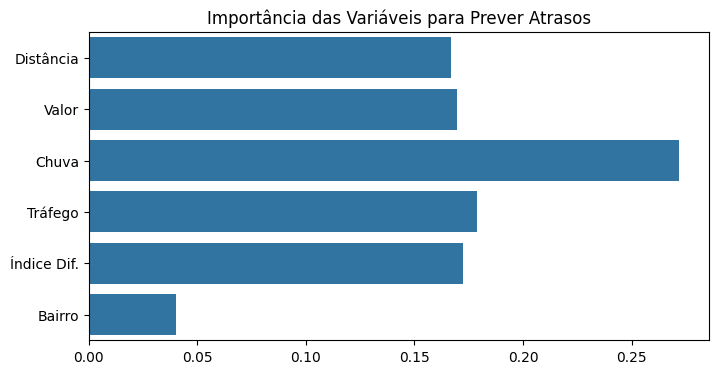


✅ PIPELINE CONCLUÍDO COM SUCESSO!


In [3]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import warnings
warnings.filterwarnings('ignore')

print("🚀 INICIANDO PIPELINE END-TO-END - P15 🚀\n")

# =====================================================================
# ETAPA 1: COLETA DE DADOS DE 2 FONTES (Simulação)
# =====================================================================
print("1️⃣ Coletando dados das fontes (Pedidos e Tráfego/Clima)...")
np.random.seed(42)
n_pedidos = 1500

# Fonte 1: Sistema interno de Pedidos
dados_pedidos = pd.DataFrame({
    'id_pedido': range(1, n_pedidos + 1),
    'distancia_km': np.random.uniform(1.0, 15.0, n_pedidos),
    'valor_pedido': np.random.uniform(20.0, 200.0, n_pedidos),
    'bairro_destino': np.random.choice(['Centro', 'Marco Zero', 'Fazendinha', 'Santana'], n_pedidos)
})

# Fonte 2: API Externa de Condições Locais
dados_condicoes = pd.DataFrame({
    'id_pedido': range(1, n_pedidos + 1),
    'chuva_mm': np.random.uniform(0.0, 50.0, n_pedidos), # Simulando chuvas no Amapá
    'trafego_pesado': np.random.choice([0, 1], n_pedidos, p=[0.7, 0.3]),
    'atraso': np.random.choice([0, 1], n_pedidos, p=[0.8, 0.2]) # Variável Alvo (Target)
})
# Forçando uma correlação para o modelo aprender: se chove muito e o trânsito é pesado, atrasa.
dados_condicoes.loc[(dados_condicoes['chuva_mm'] > 30) & (dados_condicoes['trafego_pesado'] == 1), 'atraso'] = 1

# =====================================================================
# ETAPA 2: ARMAZENAMENTO (Simulação de PostgreSQL via SQLite)
# =====================================================================
print("2️⃣ Armazenando os dados no Banco de Dados SQL...")
conn = sqlite3.connect(':memory:') # Usando memória para portabilidade no Colab
dados_pedidos.to_sql('tabela_pedidos', conn, index=False)
dados_condicoes.to_sql('tabela_condicoes', conn, index=False)

# =====================================================================
# ETAPA 3 e 4: PROCESSO ETL e ENGENHARIA DE FEATURES
# =====================================================================
print("3️⃣ e 4️⃣ Executando ETL e criando Features...")

# E (Extract): Consultando o banco de dados via SQL (Join das duas fontes)
query = """
SELECT p.id_pedido, p.distancia_km, p.valor_pedido, p.bairro_destino,
       c.chuva_mm, c.trafego_pesado, c.atraso
FROM tabela_pedidos p
JOIN tabela_condicoes c ON p.id_pedido = c.id_pedido
"""
df_bruto = pd.read_sql(query, conn)

# T (Transform) & Features:
df_etl = df_bruto.copy()
# Feature 1: Índice de Dificuldade da Entrega
df_etl['indice_dificuldade'] = df_etl['distancia_km'] * (df_etl['chuva_mm'] / 10 + 1)
# Encoding de variáveis categóricas
le = LabelEncoder()
df_etl['bairro_cod'] = le.fit_transform(df_etl['bairro_destino'])

# L (Load): Preparando X e y para Machine Learning
X = df_etl[['distancia_km', 'valor_pedido', 'chuva_mm', 'trafego_pesado', 'indice_dificuldade', 'bairro_cod']]
y = df_etl['atraso']

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# =====================================================================
# ETAPA 5 e 6: TREINAMENTO E AVALIAÇÃO DO MODELO
# =====================================================================
print("5️⃣ e 6️⃣ Treinando e Avaliando o Modelo de Machine Learning...")

modelos = {
    'Regressão Logística': LogisticRegression(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acc, 'F1-Score': f1})

    print(f"\n--- {nome} ---")
    print(classification_report(y_test, y_pred))

# Exibindo o Ranking
df_res = pd.DataFrame(resultados).sort_values('F1-Score', ascending=False)
print("\n🏆 RANKING DOS MODELOS:")
print(df_res.to_string(index=False))

# Plotando a importância das features para o Random Forest
rf_model = modelos['Random Forest']
importancias = rf_model.feature_importances_
plt.figure(figsize=(8, 4))
sns.barplot(x=importancias, y=['Distância', 'Valor', 'Chuva', 'Tráfego', 'Índice Dif.', 'Bairro'])
plt.title("Importância das Variáveis para Prever Atrasos")
plt.show()

print("\n✅ PIPELINE CONCLUÍDO COM SUCESSO!")